In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROC = Path("../data/processed")
GAS = ["H2", "CH4", "C2H6", "C2H4", "C2H2"]
LABEL = "Fail"

df = pd.read_csv(PROC / "dga_clean.csv")
print(df.shape)    

(2680, 6)


In [6]:
FLOOR = 1.0

g = df[GAS].clip(lower=FLOOR)

key = g.round(0)

profile = key.apply(tuple, axis=1)

near_dup = profile.duplicated(keep=False)

print("Rows belonging to near-duplicate groups:", near_dup.sum())

df.loc[near_dup].sort_values(GAS).head(20)

Rows belonging to near-duplicate groups: 1031


,H2,CH4,C2H6,C2H4,C2H2,Fail
578,0.0000,0.2000,0.1000,0.1300,0.0000,T2
568,0.0000,224.0000,0.0000,45.0000,0.0000,T1
810,0.0001,0.0001,0.0001,142.0000,0.0001,T3
782,0.0001,0.0001,9.0000,57.0000,0.0001,T3
856,0.0001,0.0001,10.0000,5.0000,35.0000,D2
814,0.0001,3.4000,0.0001,54.0000,0.0001,T3
774,0.0001,4.9000,81.0000,172.0000,0.0001,T2
769,0.0001,6.0000,52.0000,67.0000,0.0001,T2
918,0.0001,10.0000,17.0000,68.0000,5.0000,T3
679,0.0001,21.0000,0.0001,0.0001,40.0000,D2


In [7]:
near_rows = df.loc[near_dup].copy()

near_rows["_profile"] = profile.loc[near_dup]

label_counts = near_rows.groupby("_profile")[LABEL].nunique()

conflicting_profiles = label_counts[label_counts > 1].index

print("Near-duplicate profiles with conflicting labels:",
      len(conflicting_profiles))

near_rows[
    near_rows["_profile"].isin(conflicting_profiles)
].sort_values("_profile")

Near-duplicate profiles with conflicting labels: 13


,H2,CH4,C2H6,C2H4,C2H2,Fail,_profile
2493,0.02,0.0109,0.0559,0.0073,0.0000,T3,"(1.0, 1.0, 1.0, 1.0, 1.0)"
2490,0.21,0.7512,1.2735,0.1578,0.0000,T3,"(1.0, 1.0, 1.0, 1.0, 1.0)"
1487,1.04,1.0600,0.0000,0.7700,0.0000,NF,"(1.0, 1.0, 1.0, 1.0, 1.0)"
578,0.00,0.2000,0.1000,0.1300,0.0000,T2,"(1.0, 1.0, 1.0, 1.0, 1.0)"
1431,0.33,0.2600,0.0400,0.2700,0.0000,NF,"(1.0, 1.0, 1.0, 1.0, 1.0)"
773,0.67,0.2240,0.0450,0.0670,0.0020,T2,"(1.0, 1.0, 1.0, 1.0, 1.0)"
1523,5.92,2.6150,0.3880,0.3220,0.0000,NF,"(6.0, 3.0, 1.0, 1.0, 1.0)"
1510,5.60,3.3000,0.4000,0.3000,0.0000,NF,"(6.0, 3.0, 1.0, 1.0, 1.0)"
582,6.00,3.0000,0.8000,0.7000,0.0000,T1,"(6.0, 3.0, 1.0, 1.0, 1.0)"
733,6.00,3.0000,0.8000,0.7000,0.0001,T1,"(6.0, 3.0, 1.0, 1.0, 1.0)"


In [8]:
df = df.reset_index(drop=True)

g = df[GAS].clip(lower=1.0)

print("Dataset shape:", df.shape)

print("\nFault class counts:")
print(df[LABEL].value_counts())

Dataset shape: (2680, 6)

Fault class counts:
Fail
NF    707
T3    572
D1    336
D2    329
T1    311
T2    222
PD    203
Name: count, dtype: int64


In [9]:
feat = pd.DataFrame(index=df.index)

# Log of each gas
for c in GAS:
    feat[f"log_{c}"] = np.log10(g[c])

# Overall gas level
total = g.sum(axis=1)
feat["log_total"] = np.log10(total)

# Relative composition of each gas
for c in GAS:
    feat[f"pct_{c}"] = g[c] / total

# Duval-style gas proportions
tri = g[["CH4", "C2H4", "C2H2"]]

tri_pct = tri.div(tri.sum(axis=1), axis=0)

for c in tri_pct.columns:
    feat[f"tri_{c}"] = tri_pct[c]

# Classic gas ratios
feat["r_C2H2_C2H4"] = np.log10(g["C2H2"] / g["C2H4"])
feat["r_CH4_H2"] = np.log10(g["CH4"] / g["H2"])
feat["r_C2H4_C2H6"] = np.log10(g["C2H4"] / g["C2H6"])

X = feat
y = df[LABEL]

print(X.shape)

assert not X.isna().any().any() and np.isfinite(X.values).all()

(2680, 17)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTest class distribution:")
print(y_test.value_counts())

Training features: (2144, 17)
Testing features: (536, 17)

Test class distribution:
Fail
NF    141
T3    114
D1     67
D2     66
T1     62
T2     45
PD     41
Name: count, dtype: int64


In [11]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

models = {
    "LogReg": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=3000, class_weight="balanced"),
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "HistGB": HistGradientBoostingClassifier(
        class_weight="balanced", random_state=42
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    res = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring=["f1_macro", "accuracy"],
    )
    rows.append({
        "model": name,
        "macro_F1": res["test_f1_macro"].mean(),
        "macro_F1_std": res["test_f1_macro"].std(),
        "accuracy": res["test_accuracy"].mean(),
    })

pd.DataFrame(rows).round(3)

,model,macro_F1,macro_F1_std,accuracy
0,LogReg,0.705,0.016,0.736
1,RandomForest,0.805,0.012,0.830
2,HistGB,0.809,0.019,0.836


              precision    recall  f1-score   support

          D1       0.73      0.75      0.74       269
          D2       0.75      0.75      0.75       263
          NF       0.96      0.94      0.95       566
          PD       0.85      0.83      0.84       162
          T1       0.74      0.78      0.76       249
          T2       0.76      0.73      0.75       177
          T3       0.88      0.88      0.88       458

    accuracy                           0.84      2144
   macro avg       0.81      0.81      0.81      2144
weighted avg       0.84      0.84      0.84      2144



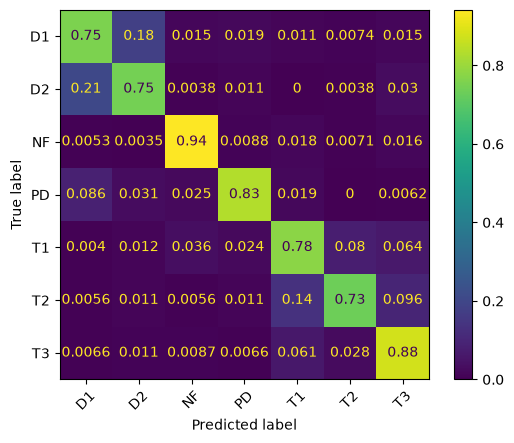

In [13]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best = models["HistGB"]     # change to whichever scored best
pred = cross_val_predict(best, X_train, y_train, cv=cv)

print(classification_report(y_train, pred))
ConfusionMatrixDisplay.from_predictions(
    y_train, pred, xticks_rotation=45, normalize="true"
)
plt.show()